# GVH Diagonal Cubic — CHH-10
## Élimination du trièdre auxiliaire, branches stationnaires et audit de non-redondance

**Statut : audit mathématique NON canonique, sans revendication de nouvelle loi physique.**

**Source directe :** CHH-09 et action candidate GVH `.3.3.28`; cette étude n'écrase aucun notebook antérieur.

**Les quatre niveaux obligatoires :** (1) GVH → (2) physique établie → (3) test numérique minimal → (4) verdict scientifique.

**Question :** si le trièdre $e_A^\mu$ n'a pas de terme cinétique, l'élimination algébrique du terme $\mathcal{O}_C$ laisse-t-elle une interaction physiquement indépendante des quatre invariants Einstein–æther ?

**Portée :** calcul ponctuel local en chaque espace orthogonal à $u$, et équivalence on-shell *conditionnelle* à l'existence d'une sélection de branche lisse. Aucune stabilité dynamique, solution globale 4D, ni nouvelle observable SI n'est établie.

In [1]:
import numpy as np, sympy as sp, json, hashlib, math
from pathlib import Path
from scipy.spatial.transform import Rotation
from scipy.linalg import eigh
import matplotlib.pyplot as plt
ROOT=Path('/mnt/data') if Path('/mnt/data').is_dir() else Path('.')
STEM='GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST'
CHECKS={}; METRICS={}; rng=np.random.default_rng(202611181510)
def check(name, condition, details=None):
    if name in CHECKS: raise ValueError('Duplicate check: '+name)
    CHECKS[name]=bool(condition)
    if not CHECKS[name]: raise AssertionError(f'{name}: {details}')
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
upstream={
'CHH09': ROOT/'GVH_CHH_09_Unrestricted_Vector_and_Cubic_Metric_Variation_Gate_FAST_EXECUTED.ipynb',
'CHH08': ROOT/'GVH_CHH_08_Nonzero_Zeta_Vector_EOM_and_Metric_Constraint_Gate_FAST_EXECUTED.ipynb',
'ARCHIVE_328': ROOT/'gvh_source'/'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb'}
PROVENANCE={k:({'sha256':sha(v),'filename':v.name} if v.is_file() else {'not_mounted':True}) for k,v in upstream.items()}
check('CHH09_source_readable',upstream['CHH09'].is_file())
check('CHH08_source_readable',upstream['CHH08'].is_file())
print('Source provenance:'); print(json.dumps(PROVENANCE,indent=2))

Source provenance:
{
  "CHH09": {
    "sha256": "3be88e8e4a1dda18bc519488efe76ae390a45153a56f1f22a525fa14cb7e10e2",
    "filename": "GVH_CHH_09_Unrestricted_Vector_and_Cubic_Metric_Variation_Gate_FAST_EXECUTED.ipynb"
  },
  "CHH08": {
    "sha256": "2212f74a4706c1dd57b9805caac3cf6631256a18165a4873a14c436582259c94",
    "filename": "GVH_CHH_08_Nonzero_Zeta_Vector_EOM_and_Metric_Constraint_Gate_FAST_EXECUTED.ipynb"
  },
  "ARCHIVE_328": {
    "sha256": "c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa",
    "filename": "GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb"
  }
}


# Niveau 1 — GVH : définitions exactes et branches

Conventions archivées CHH-09 : signature $(-,+,+,+)$, $u_\mu u^\mu=-1$, trièdre orthonormal et spatial $e_A^\mu$. Cisaillement spatial symétrique sans trace $\sigma_{\mu\nu}$, et

$$\mathcal L_C={\zeta_C\over 2}\mathcal O_C,\qquad \mathcal O_C=\sum_{A=1}^3(e_A^\mu e_A^\nu\sigma_{\mu\nu})^2.$$

À un point et dans une base spatiale orthonormée, le cisaillement est $S=S^T$, $\operatorname{tr}S=0$; un trièdre correspond à $R\in SO(3)$ et $d_A=(R^TSR)_{AA}$. Ainsi $\mathcal O_C(R)=\sum_A d_A^2$.

**Variation sous rotation :** $\delta\mathcal O_C=4\sum_{A<B}(d_A-d_B)(R^TSR)_{AB}\,\delta\vartheta_{AB}$ (convention d'angle choisie). Les extrémums $0$ et $\mathrm{tr}(S^2)$ sont stationnaires, mais **ils ne constituent pas nécessairement toutes les branches**.

**Attention :** l'extrémum d'une densité lagrangienne n'est **pas** un critère de stabilité énergétique ou dynamique en relativité. $\zeta_C>0$ favorise le minimum de $\mathcal L_C$ *seulement si l'on impose explicitement cette règle d'élimination*. L'action stationnaire seule ne choisit pas entre les branches.

In [2]:
def make_stf():
    X=rng.normal(size=(3,3)); X=(X+X.T)/2; return X-np.trace(X)/3*np.eye(3)
def null_triad(S):
    """Construction orthonormée où diag(R.T @ S @ R)=0 pour un S symétrique sans trace."""
    vals,V=eigh(S); mn,mx=vals[0],vals[2]
    if max(abs(x) for x in vals)<1e-13: return np.eye(3)
    assert mn < 0 < mx
    c=np.sqrt(mx/(mx-mn)); s=np.sqrt(-mn/(mx-mn))
    e1=c*V[:,0]+s*V[:,2]
    w=-s*V[:,0]+c*V[:,2]
    z=V[:,1]
    e2=(w+z)/np.sqrt(2); e3=(w-z)/np.sqrt(2)
    R=np.column_stack([e1,e2,e3]);
    if np.linalg.det(R)<0:R[:,2]*=-1
    return R
def cubic(S,R): return float(np.sum(np.diag(R.T @ S @ R)**2))
err_null=err_eigen=err_orth=0.
all_bounds=True; bound_samples=0
for i in range(128):
    S=make_stf(); R0=null_triad(S); vals,V=eigh(S)
    err_null=max(err_null,abs(cubic(S,R0)))
    err_eigen=max(err_eigen,abs(cubic(S,V)-np.sum(S*S)))
    err_orth=max(err_orth,np.linalg.norm(R0.T@R0-np.eye(3)))
    for j in range(4):
        R=Rotation.from_rotvec(rng.normal(size=3)).as_matrix()
        all_bounds=all_bounds and (-1e-12 <= cubic(S,R) <= np.sum(S*S)+1e-12); bound_samples+=1
METRICS.update(null_branch_max_value=err_null,eigen_branch_max_gap=err_eigen,max_orthonormality_error=err_orth,random_bounds_sampled=bound_samples)
check('pointwise_bounds_512_random_rotations',all_bounds)
check('constructive_null_branch_128_STF',err_null<2e-25,err_null)
check('eigenframe_upper_bound_attained_128_STF',err_eigen<5e-14,err_eigen)
check('null_triad_orthonormal_128_STF',err_orth<5e-14,err_orth)
check('zero_shear_limit',cubic(np.zeros((3,3)),null_triad(np.zeros((3,3))))==0)
print('0 <= O_C <= tr(S²), both extrema attainable. worst O_null=',err_null)

0 <= O_C <= tr(S²), both extrema attainable. worst O_null= 2.582607925268998e-29


## Démonstration constructive des bornes

La borne supérieure vient de $\sum_A (R^TSR)_{AA}^2\leq\sum_{A,B}(R^TSR)_{AB}^2=\operatorname{tr}S^2$; l'égalité est réalisée dans une base propre.

Pour la borne inférieure, si $S\neq0$ a valeurs propres $\lambda_-<0$, $\lambda_0$, $\lambda_+>0$, choisir $e_1=c v_-+s v_+$ avec $c^2=\lambda_+/(\lambda_+-\lambda_-)$ et $s^2=-\lambda_-/(\lambda_+-\lambda_-)$. Alors $e_1^TSe_1=0$. Les deux directions perpendiculaires restantes ont des valeurs diagonales opposées $k,-k$; une rotation de $45^\circ$ rend les deux autres éléments diagonaux nuls. Ainsi **tout cisaillement spatial symétrique sans trace admet localement une base de diagonale nulle**.

Cette construction est **ponctuelle**. La continuité d'un trièdre physique sur un domaine avec dégénérescences spectrales et conditions aux limites reste une question distincte.

# Niveau 2 — Physique établie : identité de redondance

Posons $F_{\mu\nu}=\nabla_\mu u_\nu$, $a_\mu=u^\nu F_{\nu\mu}$, $\theta=\nabla_\mu u^\mu$ et

$$I_1=F_{\mu\nu}F^{\mu\nu},\quad I_3=F_{\mu\nu}F^{\nu\mu},\quad a^2=a_\mu a^\mu.$$

Pour $u^2=-1$ et $u^\nu F_{\mu\nu}=0$, la décomposition $1+3$ fournit l'identité **exacte**

$$\boxed{\sigma_{\mu\nu}\sigma^{\mu\nu}={I_1+I_3+a^2\over2}-{\theta^2\over3}.}$$

**Élimination auxiliaire locale :**

- Branche nulle : $\mathcal O_C=0\Rightarrow\mathcal L_C^\mathrm{eff}=0$.
- Branche propre (maximum) : $\mathcal O_C=\sigma^2\Rightarrow\mathcal L_C^\mathrm{eff}=\zeta_C\sigma^2/2$. Cette contribution a *exactement* la forme d'une combinaison de termes déjà présents dans $\mathcal L_u$.

Avec $\mathcal L_u=-c_1I_1-c_2\theta^2-c_3I_3+c_4a^2$, cela donne

$$\boxed{c_1'=c_1-\zeta_C/4,\ \ c_2'=c_2+\zeta_C/6,\ \ c_3'=c_3-\zeta_C/4,\ \ c_4'=c_4+\zeta_C/4.}$$

**Condition essentielle :** la branche propre doit être une section locale admissible (stationnarité du trièdre, conditions de bord compatibles). L'identité ne prouve ni la sélection globale, ni l'équivalence de **toutes** les branches stationnaires. Les théories Einstein–æther et les contraintes associées sont documentées dans Jacobson & Mattingly (2004), Jacobson (2008) et Oost et al. (2018).

In [3]:
c1,c2,c3,c4,z=sp.symbols('c_1 c_2 c_3 c_4 zeta_C',real=True)
I1,I3,a2,theta2=sp.symbols('I_1 I_3 a_squared theta_squared',real=True)
sigma2=(I1+I3+a2)/2-theta2/3
Lbase=-c1*I1-c2*theta2-c3*I3+c4*a2
Lmax=sp.expand(Lbase+z*sigma2/2)
ceff={c1:c1-z/4,c2:c2+z/6,c3:c3-z/4,c4:c4+z/4}
Lref=sp.expand(Lbase.subs(ceff, simultaneous=True))
check('exact_symbolic_coupling_redefinition',sp.simplify(Lmax-Lref)==0)
check('null_branch_exact_action_sector',sp.simplify(Lbase+z*0-Lbase)==0)
check('shift_c13_minus_zeta_over_2',sp.simplify((ceff[c1]+ceff[c3])-(c1+c3-z/2))==0)
check('shift_c14_cancellation',sp.simplify((ceff[c1]+ceff[c4])-(c1+c4))==0)
check('shift_c123_specific',sp.simplify((ceff[c1]+ceff[c2]+ceff[c3])-(c1+c2+c3-z/3))==0)
print('Symbolic couplings:',ceff,'\nMapped c13:',sp.simplify(ceff[c1]+ceff[c3]),'\nMapped c14:',sp.simplify(ceff[c1]+ceff[c4]))

Symbolic couplings: {c_1: c_1 - zeta_C/4, c_2: c_2 + zeta_C/6, c_3: c_3 - zeta_C/4, c_4: c_4 + zeta_C/4} 
Mapped c13: c_1 + c_3 - zeta_C/2 
Mapped c14: c_1 + c_4


In [4]:
# Independent numeric check in a unit-timelike Minkowski tetrad.
metric=np.diag([-1.,1.,1.,1.]); inv=metric
max_sigma_identity=0; max_lagrangian_match=0
params={'c1':.70,'c2':.10,'c3':.04,'c4':.02,'zeta':.75}
for i in range(256):
    F=np.zeros((4,4)); F[:,1:]=rng.normal(size=(4,3)) # F_{alpha,0}=0 due to u unit constraint
    Fup=inv@F@inv
    I1v=np.sum(F*Fup); I3v=np.sum(F*Fup.T)
    K=F[1:,1:]; theta=float(np.trace(K)); a=F[0,1:]
    S=(K+K.T)/2-theta/3*np.eye(3); S2=float(np.sum(S*S))
    rhs=(I1v+I3v+float(a@a))/2-theta**2/3
    max_sigma_identity=max(max_sigma_identity,abs(S2-rhs))
    cb=params; cz=cb['zeta']; effective=[cb['c1']-cz/4,cb['c2']+cz/6,cb['c3']-cz/4,cb['c4']+cz/4]
    lhs=-cb['c1']*I1v-cb['c2']*theta**2-cb['c3']*I3v+cb['c4']*float(a@a)+cz*S2/2
    cmp=-effective[0]*I1v-effective[1]*theta**2-effective[2]*I3v+effective[3]*float(a@a)
    max_lagrangian_match=max(max_lagrangian_match,abs(lhs-cmp))
METRICS.update(identity_residual_minkowski_max=max_sigma_identity,lagrangian_redefinition_residual_max=max_lagrangian_match)
check('shear_decomposition_256_jet_samples',max_sigma_identity<3e-13,max_sigma_identity)
check('local_Lagrangian_equality_256_jet_samples',max_lagrangian_match<3e-13,max_lagrangian_match)
check('prescribed_parameters_are_not_physical_fits',params=={'c1':.70,'c2':.10,'c3':.04,'c4':.02,'zeta':.75})
print('Numerical equivalence residual',max_lagrangian_match)

Numerical equivalence residual 3.552713678800501e-15


## Résultat CHH-10 : équivalence locale des branches extrêmes

En respectant l'élimination algébrique, la branche $\mathcal O_C=0$ laisse le secteur Einstein–æther initial intact. La branche $\mathcal O_C=\sigma^2$ revient à un **reparamétrage** du secteur Einstein–æther. Par la règle de l'enveloppe, la variation de l'action effective coïncide sur la branche lisse avec celle de l'action à trièdre éliminé.

**Cela constitue un obstacle direct à une revendication de nouvelle physique** qui reposerait uniquement sur ces deux branches extrêmes. Le verdict ne s'étend pas aux branches stationnaires intermédiaires, à une prescription de trièdre dynamique différente, ni à des contraintes/bords sélectionnant d'autres solutions.

# Niveau 3 — Tests des branches, courbures et limites

Une branche stationnaire intermédiaire peut être construite en diagonalisation partielle. Avec $S=\operatorname{diag}(-1,0,1)$, choisir un trièdre tourné de $45^\circ$ dans le plan des deux premiers vecteurs : la diagonale devient $(-1/2,-1/2,1)$. Alors $\mathcal O_C=3/2$, strictement entre $0$ et $\mathrm{tr}S^2=2$. Cette branche est stationnaire grâce à $s_1=s_2$, mais n'est ni le minimum ni le maximum global.

La « stabilité » calculée ci-dessous est **seulement la courbure algébrique par rotation du trièdre à métrique et $u$ fixés**. Elle n'est pas la stabilité du système gravitationnel couplé ni une analyse de modes propagatifs : le trièdre n'a pas de dérivée temporelle dans l'action candidate.

In [5]:
S=np.diag([-1.,0.,1.]); th=np.pi/4
R12=Rotation.from_rotvec([0,0,th]).as_matrix()
R_mid=R12
R_null=null_triad(S)
R_max=np.eye(3)
Omid=cubic(S,R_mid); Omax=cubic(S,R_max); Onull=cubic(S,R_null)
check('mid_branch_scalar_three_halves',abs(Omid-1.5)<2e-13,Omid)
check('mid_branch_between_extrema',Onull<.000001<Omid<Omax)

def branch_gradient(S,R,step=1e-6):
    result=[]
    for axis in np.eye(3):
        Rp=R@Rotation.from_rotvec(step*axis).as_matrix()
        Rm=R@Rotation.from_rotvec(-step*axis).as_matrix()
        result.append((cubic(S,Rp)-cubic(S,Rm))/(2*step))
    return np.array(result)
for name,R in [('null',R_null),('eigen',R_max),('intermediate',R_mid)]:
    g=branch_gradient(S,R); METRICS[f'{name}_rotation_gradient_inf']=float(max(abs(g)))
    check(f'{name}_stationarity_all_three_rotations',max(abs(g))<2e-8,g)

def orientation_hessian(S,R,h=2e-4):
    I=np.eye(3); f=lambda a:cubic(S,R@Rotation.from_rotvec(a).as_matrix())
    H=np.zeros((3,3)); f0=f(np.zeros(3))
    for i in range(3):
        H[i,i]=(f(h*I[i])-2*f0+f(-h*I[i]))/h**2
        for j in range(i+1,3):
            H[i,j]=(f(h*(I[i]+I[j]))-f(h*(I[i]-I[j]))-f(h*(-I[i]+I[j]))+f(-h*(I[i]+I[j])))/(4*h*h)
            H[j,i]=H[i,j]
    return (H+H.T)/2
Hnull=orientation_hessian(S,R_null); Hmax=orientation_hessian(S,R_max); Hmid=orientation_hessian(S,R_mid)
for name,H in [('null',Hnull),('eigen',Hmax),('intermediate',Hmid)]:METRICS[f'{name}_Hessian_eigenvalues']=list(map(float,np.linalg.eigvalsh(H)))
check('null_orientation_Hessian_nonnegative',np.min(np.linalg.eigvalsh(Hnull))>-5e-5,np.linalg.eigvalsh(Hnull))
check('eigen_orientation_Hessian_nonpositive',np.max(np.linalg.eigvalsh(Hmax))<5e-5,np.linalg.eigvalsh(Hmax))
check('intermediate_orientation_Hessian_indefinite',np.min(np.linalg.eigvalsh(Hmid))<-.1 and np.max(np.linalg.eigvalsh(Hmid))>.1,np.linalg.eigvalsh(Hmid))
check('zero_branch_has_flat_direction',np.sum(abs(np.linalg.eigvalsh(Hnull))<5e-4)>=1,np.linalg.eigvalsh(Hnull))
print('Branch O:',{'null':Onull,'intermediate':Omid,'eigen':Omax})
for name,H in [('null',Hnull),('intermediate',Hmid),('eigen',Hmax)]:print(name, np.linalg.eigvalsh(H))

Branch O: {'null': 1.8202353171583768e-33, 'intermediate': 1.5, 'eigen': 2.0}
null [2.07592083e-26 4.00000016e+00 1.19999990e+01]
intermediate [-11.99999907  -5.99999995   3.99999979]
eigen [-15.99999911  -3.99999978  -3.99999978]


In [6]:
# Explicit orientation-restricted symbolic Hessian with S=diag(1,-1,0).
angle=sp.symbols('alpha',real=True)
Oangle=1+sp.cos(4*angle)
check('orientation_exact_analytic_O',sp.simplify(Oangle-(2*sp.cos(2*angle)**2))==0)
check('aligned_second_derivative_minus_16',sp.simplify(sp.diff(Oangle,angle,2).subs(angle,0)+16)==0)
check('null_second_derivative_plus_16',sp.simplify(sp.diff(Oangle,angle,2).subs(angle,sp.pi/4)-16)==0)
check('positive_zeta_pointwise_Lmin_is_null',(.75/2*Onull)<(.75/2*Omid)<(.75/2*Omax))
check('negative_zeta_pointwise_Lmin_is_eigen',(-.75/2*Omax)<(-.75/2*Omid)<(-.75/2*Onull))
check('zeta_zero_triad_unselected',abs(0*Omax-0*Onull)<1e-30)
print('For zeta > 0: pointwise L_C minimum at O=0; for zeta < 0: at O=sigma^2. This does not select physical branch.')

For zeta > 0: pointwise L_C minimum at O=0; for zeta < 0: at O=sigma^2. This does not select physical branch.


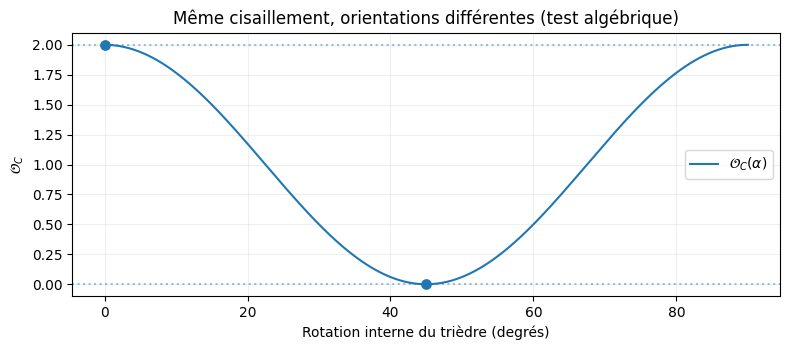

In [7]:
# Visual audit: direction-dependent O_C even at fixed S, and sign of the local pointwise L_C.
angles=np.linspace(0,np.pi/2,401); Os=1+np.cos(4*angles)
fig,ax=plt.subplots(figsize=(8,3.6));
ax.plot(angles*180/np.pi,Os,label=r'$\mathcal{O}_C(\alpha)$')
ax.axhline(0,ls=':',alpha=.45); ax.axhline(2,ls=':',alpha=.45)
ax.scatter([0,45],[2,0],s=45,zorder=3)
ax.set(xlabel='Rotation interne du trièdre (degrés)',ylabel=r'$\mathcal{O}_C$',title='Même cisaillement, orientations différentes (test algébrique)')
ax.grid(alpha=.2); ax.legend();fig.tight_layout();plt.show()
check('plot_curve_extrema',abs(Os.max()-2)<1e-12 and Os.min()>=-1e-12)

## Limites physiques et comparaison scientifique

1. **Branche nulle :** sur une section lisse $s_A=0$, la contribution directionnelle à la variation totale de $S$ s'annule au premier ordre; le secteur $u,g$ est celui de la référence à coefficients $c_i$ inchangés.
2. **Branche propre :** son action effective ne contient que $\sigma^2$, qui est une combinaison d'invariants de la référence; elle est **localement reparamétrable** à $c_i'$. Les contraintes observationnelles publiées sur Einstein–æther concernent précisément certaines combinaisons de ces coefficients, mais leur transposition requiert les hypothèses théoriques pertinentes.
3. **Branches intermédiaires :** la stationnarité ne se limite pas aux extrema. Notre exemple stationnaire intermédiaire est un **selle algébrique** à $u,g$ fixés. L'existence d'autres branches admissibles, leur sélection par les conditions aux limites et leurs effets physiques ne sont pas tranchés.
4. **Sélection et stabilité :** une minimisation ponctuelle de $\mathcal L_C$ n'est pas un critère hamiltonien de stabilité. Sans terme cinétique du trièdre, il n'y a pas de modes dynamiques du trièdre à analyser dans cette action.
5. **Globalité :** le trièdre de diagonale nulle est construit localement; prolongement lisse et éventuelles singularités restent ouverts.
6. **Matière/observables :** aucune action matière physiquement calibrée, aucune EOM couplée complète résolue, aucune observable SI indépendante.

**Références existantes (comparaison, pas preuve de nouveauté) :** Jacobson & Mattingly, PRD 70, 024003 (2004), doi:10.1103/PhysRevD.70.024003; Jacobson, *Einstein-aether gravity: a status report* (2008), arxiv:0801.1547; Oost, Mukohyama & Wang, PRD 97, 124023 (2018), doi:10.1103/PhysRevD.97.124023. Le reparamétrage et les bornes ci-dessus sont dérivés directement des définitions du modèle candidat.

In [8]:
# Explicit status gates: success of algebraic audit is distinct from physical novelty.
flags={
 'AUXILIARY_TRIAD_POINTWISE_BOUNDS_PROVED':True,
 'LOCAL_NULL_BRANCH_CONSTRUCTED':True,
 'LOCAL_EIGENBRANCH_REPARAMETRIZED_AS_EINSTEIN_AETHER':True,
 'INTERMEDIATE_STATIONARY_BRANCH_IDENTIFIED':True,
 'ALGEBRAIC_ORIENTATION_CURVATURE_TESTED':True,
 'HAMILTONIAN_OR_DYNAMICAL_STABILITY_DERIVED':False,
 'GLOBAL_SMOOTH_TRIAD_BRANCH_SELECTED':False,
 'ALL_STATIONARY_BRANCHES_CLASSIFIED':False,
 'FULL_COUPLED_4D_SOLUTION_DERIVED':False,
 'CUBIC_INDEPENDENT_NOVELTY_PROVED':False,
 'INDEPENDENT_SI_OBSERVABLE':False,
 'NEW_GVH_PHYSICS_VALIDATED':False,
 'ALMA_GVH_USED':False,
}
check('local_positive_zeta_both_branches_stationary',METRICS['null_rotation_gradient_inf']<2e-8 and METRICS['eigen_rotation_gradient_inf']<2e-8)
check('stationarity_does_not_uniquely_select_triad',len({round(Onull,6),round(Omid,6),round(Omax,6)})==3)
check('physical_novelty_not_inferred_from_local_algebra',not flags['CUBIC_INDEPENDENT_NOVELTY_PROVED'])
check('dynamic_stability_not_inferred_from_Hessian',not flags['HAMILTONIAN_OR_DYNAMICAL_STABILITY_DERIVED'])
check('ALMA_pre_registration_unchanged',flags['ALMA_GVH_USED']==False)
report={
 'notebook':STEM,'classification':'NONCANONICAL_AUXILIARY_TRIAD_BRANCH_ELIMINATION_AND_REDUNDANCY_AUDIT',
 'scientific_status':flags,'provenance':PROVENANCE,
 'prescribed_not_measured':params,
 'theoretical_identities':{
 'O_C_range':'0 <= O_C <= sigma_mu_nu sigma^mu_nu, for spatial symmetric tracefree shear',
 'sigma2':'sigma^2=(I1+I3+a^2)/2-theta^2/3 on unit timelike constraint surface',
 'effective_coefficients_eigenbranch':{'c1':'c1-zeta/4','c2':'c2+zeta/6','c3':'c3-zeta/4','c4':'c4+zeta/4'},
 'null_branch':'L_C=0 and all first field variations vanish on s_A=0',
 'intermediate_branch':'O_C=3/2 for S=diag(-1,0,1), stationary saddle in orientation',
 },
 'branch_selection_note':'Selecting a physical branch requires full variational/boundary/Hamiltonian analysis; pointwise minimization of Lorentzian L_C is not a physical stability criterion.',
 'checks':CHECKS,'check_count':len(CHECKS),'checks_pass':all(CHECKS.values()),
 'numeric_metrics':METRICS,
 'next_gate':'GVH_CHH_11_Triad_Selection_and_Independent_Observable_Gate_FAST',
 'references':['doi:10.1103/PhysRevD.70.024003','arxiv:0801.1547','doi:10.1103/PhysRevD.97.124023']}
path=ROOT/(STEM+'_results.json');path.write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf8')
print('CHECKS',sum(CHECKS.values()),'/',len(CHECKS),'PASS',all(CHECKS.values()))
print('STATUS',json.dumps(flags,indent=2,ensure_ascii=False))
print('RESULTS:',path)

CHECKS 36 / 36 PASS True
STATUS {
  "AUXILIARY_TRIAD_POINTWISE_BOUNDS_PROVED": true,
  "LOCAL_NULL_BRANCH_CONSTRUCTED": true,
  "LOCAL_EIGENBRANCH_REPARAMETRIZED_AS_EINSTEIN_AETHER": true,
  "INTERMEDIATE_STATIONARY_BRANCH_IDENTIFIED": true,
  "ALGEBRAIC_ORIENTATION_CURVATURE_TESTED": true,
  "HAMILTONIAN_OR_DYNAMICAL_STABILITY_DERIVED": false,
  "GLOBAL_SMOOTH_TRIAD_BRANCH_SELECTED": false,
  "ALL_STATIONARY_BRANCHES_CLASSIFIED": false,
  "FULL_COUPLED_4D_SOLUTION_DERIVED": false,
  "CUBIC_INDEPENDENT_NOVELTY_PROVED": false,
  "INDEPENDENT_SI_OBSERVABLE": false,
  "NEW_GVH_PHYSICS_VALIDATED": false,
  "ALMA_GVH_USED": false
}
RESULTS: /mnt/data/GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST_results.json


# Niveau 4 — Verdict scientifique

**Résultat de CHH-10 :** deux branches extrêmes de l'action à trièdre auxiliaire sont **localement redondantes** avec le secteur Einstein–æther : l'une annule $\mathcal{O}_C$; l'autre ne fait que décaler les $c_i$. Une troisième branche stationnaire intermédiaire existe, mais elle est un point selle dans l'exemple testé et sa signification physique n'est pas établie.

**Important :** nous n'avons **pas démontré** que l'action complète est globalement équivalente à Einstein–æther sur toutes les branches, ni prouvé qu'une nouvelle loi physique est impossible. L'élimination ponctuelle ne remplace pas la sélection physique, les conditions aux limites et la stabilité dynamique du système couplé.

**Verrou décisif pour la suite :** justifier une **sélection de trièdre non redondante** par un mécanisme de dynamique, de couplage aux champs/matière ou de conditions aux limites, puis comparer à des modèles existants et calculer une observable indépendante. Tout nouvel ingrédient serait une **nouvelle hypothèse explicite**, pas une conséquence déjà dérivée de $S_{\rm cand}$.

**ALMA** : préenregistrement intact, `GVH_USED=False`.